# Phase 9 — Forward-Return Target Engineering
## Australian Stock Market Analytics

### Goal
Turn acquired historical market prices into well-defined, dated prediction targets for a future modeling phase.

This notebook:
1. loads Phase 8 company prices and benchmark data;
2. validates ticker/date uniqueness, price fields, and coverage;
3. computes forward returns using future adjusted-price observations;
4. computes matching benchmark forward returns where available;
5. creates benchmark-relative return targets;
6. documents label availability and prevents using future data as predictors;
7. saves target datasets and coverage reports.

**Critical:** Targets use future observations by design. They are labels only—not predictors. Do not randomly split rows for later modeling; use chronological validation and ensure each prediction's features were available on its prediction date. The notebook does not train a model or give investment advice.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")
print("Imports successful.")

Imports successful.


## 2. Locate Phase 8 market-data outputs

In [2]:
PROJECT_ROOT = None
company_file = None
benchmark_file = None

for base in [Path.cwd(), *Path.cwd().parents]:
    candidate = base / "data" / "processed" / "market_data" / "asx_company_daily_prices.csv"
    if candidate.exists():
        PROJECT_ROOT = base
        company_file = candidate
        possible_benchmark = base / "data" / "processed" / "market_data" / "asx200_benchmark_daily.csv"
        benchmark_file = possible_benchmark if possible_benchmark.exists() else None
        break

if company_file is None:
    raise FileNotFoundError(
        "Cannot find data/processed/market_data/asx_company_daily_prices.csv. "
        "Run Phase 8 and verify the saved output path."
    )

TARGET_DIR = PROJECT_ROOT / "data" / "processed" / "model_targets"
REPORT_DIR = PROJECT_ROOT / "reports" / "target_engineering"
TARGET_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

prices = pd.read_csv(company_file)
print("Company prices:", company_file)
print("Raw shape:", prices.shape)
print("Benchmark file:", benchmark_file)
display(prices.head())

Company prices: e:\Projects\Australian Stock Market Data Science Project\data\processed\market_data\asx_company_daily_prices.csv
Raw shape: (65771, 8)
Benchmark file: e:\Projects\Australian Stock Market Data Science Project\data\processed\market_data\asx200_benchmark_daily.csv


,date,close,high,low,open,volume,yahoo_symbol,ticker
0,2021-10-19,6.45814,6.46741,6.14311,6.14311,5232326,A2M.AX,A2M
1,2021-10-20,6.84730,6.90289,6.48594,6.53227,15237359,A2M.AX,A2M
2,2021-10-21,6.60639,6.84730,6.56933,6.84730,6015791,A2M.AX,A2M
3,2021-10-22,6.38402,6.59713,6.34695,6.59713,6359080,A2M.AX,A2M
4,2021-10-25,6.30063,6.43961,6.27283,6.39328,4083248,A2M.AX,A2M


## 3. Normalize schema and validate required columns

In [3]:
prices.columns = [str(c).strip().lower() for c in prices.columns]
rename_candidates = {
    "ticker_symbol": "yahoo_symbol",
    "source_ticker": "ticker",
    "adjusted_close": "adj_close"
}
prices = prices.rename(columns={c: rename_candidates[c] for c in prices.columns if c in rename_candidates})

required = {"date", "ticker", "close"}
missing = required - set(prices.columns)
if missing:
    raise ValueError(f"Missing required columns in company price data: {sorted(missing)}")

prices["date"] = pd.to_datetime(prices["date"], errors="coerce", utc=True).dt.tz_localize(None)
prices["ticker"] = prices["ticker"].astype(str).str.strip().str.upper()
prices["close"] = pd.to_numeric(prices["close"], errors="coerce")

if "adj_close" in prices.columns:
    prices["adj_close"] = pd.to_numeric(prices["adj_close"], errors="coerce")
else:
    # Phase 8 used auto_adjust=True; in that case close is adjusted by yfinance.
    prices["adj_close"] = prices["close"]
    print("No adj_close column found; using close because Phase 8 configured auto_adjust=True.")

# Use adjusted close where available; fall back to close only if adjusted close is missing.
prices["price_for_returns"] = prices["adj_close"].where(
    prices["adj_close"].notna(), prices["close"]
)
prices = prices.dropna(subset=["date", "ticker"]).sort_values(["ticker", "date"]).reset_index(drop=True)

quality = {
    "rows": len(prices),
    "tickers": prices["ticker"].nunique(),
    "duplicate_ticker_date_rows": int(prices.duplicated(["ticker", "date"]).sum()),
    "missing_return_price": int(prices["price_for_returns"].isna().sum()),
    "nonpositive_return_price": int((prices["price_for_returns"] <= 0).fillna(False).sum()),
    "date_min": str(prices["date"].min()),
    "date_max": str(prices["date"].max())
}
display(pd.DataFrame([quality]))

if prices.duplicated(["ticker", "date"]).any():
    dupes = prices.loc[prices.duplicated(["ticker", "date"], keep=False)].sort_values(["ticker", "date"])
    dupes.to_csv(REPORT_DIR / "duplicate_company_ticker_dates.csv", index=False)
    raise ValueError("Duplicate ticker/date rows found. Resolve duplicates before target engineering.")

prices = prices.loc[
    prices["price_for_returns"].notna() & (prices["price_for_returns"] > 0)
].copy()
prices = prices.sort_values(["ticker", "date"]).reset_index(drop=True)

No adj_close column found; using close because Phase 8 configured auto_adjust=True.


,rows,tickers,duplicate_ticker_date_rows,missing_return_price,nonpositive_return_price,date_min,date_max
0,65771,52,0,0,0,2021-10-19 00:00:00,2026-10-19 00:00:00


## 4. Inspect historical coverage before creating targets

,ticker,observations,first_date,last_date,unique_dates,calendar_days
43,STP,1256,2021-11-01,2026-10-19,1256,1813
0,A2M,1265,2021-10-19,2026-10-19,1265,1826
2,ADH,1265,2021-10-19,2026-10-19,1265,1826
1,ACL,1265,2021-10-19,2026-10-19,1265,1826
4,ALD,1265,2021-10-19,2026-10-19,1265,1826
5,ANN,1265,2021-10-19,2026-10-19,1265,1826
6,ANZ,1265,2021-10-19,2026-10-19,1265,1826
3,AFG,1265,2021-10-19,2026-10-19,1265,1826
8,ASG,1265,2021-10-19,2026-10-19,1265,1826
9,ASH,1265,2021-10-19,2026-10-19,1265,1826


,observation_count_statistics
count,52.00000
mean,"1,264.82692"
std,1.24808
min,"1,256.00000"
25%,"1,265.00000"
50%,"1,265.00000"
75%,"1,265.00000"
max,"1,265.00000"


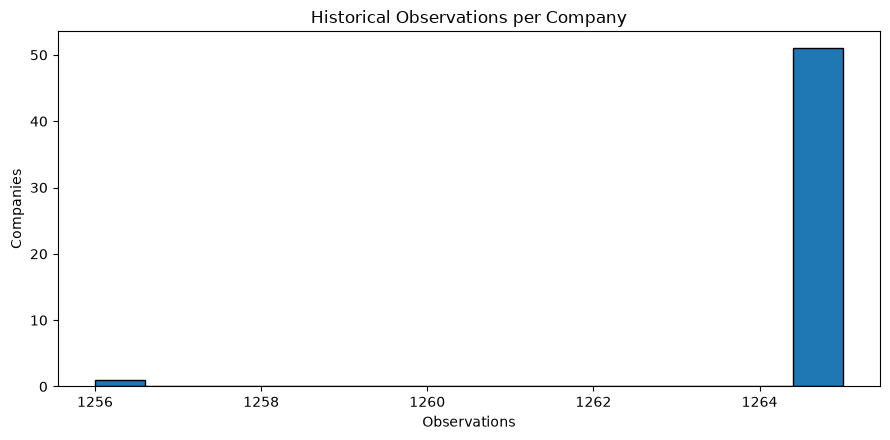

In [4]:
coverage = (
    prices.groupby("ticker")
    .agg(
        observations=("date", "size"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        unique_dates=("date", "nunique")
    )
    .reset_index()
)
coverage["calendar_days"] = (coverage["last_date"] - coverage["first_date"]).dt.days
display(coverage.sort_values("observations").head(15))
display(coverage["observations"].describe().to_frame("observation_count_statistics"))
coverage.to_csv(REPORT_DIR / "company_history_coverage_before_targets.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(coverage["observations"], bins=15, edgecolor="black")
ax.set(title="Historical Observations per Company", xlabel="Observations", ylabel="Companies")
plt.tight_layout()
plt.show()

## 5. Define target horizons

In [5]:
# Trading-session approximations. These are not exact calendar-month forecasts.
HORIZONS = {
    "1m": 21,
    "3m": 63,
    "6m": 126
}
MIN_PRICE = 0

print("Forward-return horizons (trading observations):", HORIZONS)

Forward-return horizons (trading observations): {'1m': 21, '3m': 63, '6m': 126}


## 6. Create forward-return labels per company

For a horizon of `h` trading observations, the forward return is:

\[
R_{t,t+h} = \frac{P_{t+h}}{P_t} - 1
\]

The target is aligned to the prediction date `t`, but it uses a future price at `t+h`. Rows near the end of each ticker's history will have missing labels because the future outcome is not yet observed. Those rows must not be filled with zero.

In [6]:
targets = prices.copy()
targets = targets.sort_values(["ticker", "date"]).reset_index(drop=True)

for horizon_name, steps in HORIZONS.items():
    future_price_col = f"future_price_{horizon_name}"
    forward_return_col = f"forward_return_{horizon_name}"

    targets[future_price_col] = (
        targets.groupby("ticker", sort=False)["price_for_returns"].shift(-steps)
    )
    targets[forward_return_col] = (
        targets[future_price_col] / targets["price_for_returns"] - 1
    )

display(targets[[
    "ticker", "date", "price_for_returns",
    "future_price_1m", "forward_return_1m",
    "future_price_3m", "forward_return_3m",
    "future_price_6m", "forward_return_6m"
]].head(10))

,ticker,date,price_for_returns,future_price_1m,forward_return_1m,future_price_3m,forward_return_3m,future_price_6m,forward_return_6m
0,A2M,2021-10-19,6.45814,5.64277,-0.12626,4.97564,-0.22956,4.34558,-0.32712
1,A2M,2021-10-20,6.84730,5.68909,-0.16915,4.94784,-0.27740,4.24366,-0.38024
2,A2M,2021-10-21,6.60639,5.75395,-0.12903,4.74400,-0.28191,4.16953,-0.36886
3,A2M,2021-10-22,6.38402,5.75395,-0.09869,4.71620,-0.26125,4.06761,-0.36284
4,A2M,2021-10-25,6.30063,5.84661,-0.07206,5.04977,-0.19853,4.04908,-0.35735
5,A2M,2021-10-26,6.34695,5.84661,-0.07883,4.85519,-0.23504,4.13247,-0.34891
6,A2M,2021-10-27,5.58717,5.68909,0.01824,4.82739,-0.13599,4.05834,-0.27363
7,A2M,2021-10-28,5.67983,5.55938,-0.02121,4.86445,-0.14356,4.02128,-0.29201
8,A2M,2021-10-29,5.79102,5.55011,-0.04160,4.86445,-0.16000,3.89156,-0.32800
9,A2M,2021-11-01,5.75395,5.48525,-0.04670,4.93858,-0.14171,3.94716,-0.31401


## 7. Load and align benchmark data (if available)

In [7]:
benchmark = None
benchmark_status = "unavailable"

if benchmark_file is not None:
    benchmark = pd.read_csv(benchmark_file)
    benchmark.columns = [str(c).strip().lower() for c in benchmark.columns]
    benchmark = benchmark.rename(columns={
        "ticker_symbol": "yahoo_symbol",
        "source_ticker": "ticker",
        "adjusted_close": "adj_close"
    })
    if "date" in benchmark.columns:
        benchmark["date"] = pd.to_datetime(
            benchmark["date"], errors="coerce", utc=True
        ).dt.tz_localize(None)
    if "close" in benchmark.columns:
        benchmark["close"] = pd.to_numeric(benchmark["close"], errors="coerce")
    if "adj_close" in benchmark.columns:
        benchmark["adj_close"] = pd.to_numeric(benchmark["adj_close"], errors="coerce")
    else:
        benchmark["adj_close"] = benchmark.get("close")

    benchmark["benchmark_price"] = benchmark["adj_close"].where(
        benchmark["adj_close"].notna(), benchmark["close"]
    )
    benchmark = benchmark.dropna(subset=["date", "benchmark_price"]).sort_values("date")
    benchmark = benchmark.drop_duplicates(subset=["date"], keep="last")
    benchmark_status = "loaded" if not benchmark.empty else "empty"

print("Benchmark status:", benchmark_status)
if benchmark is not None and not benchmark.empty:
    print("Benchmark observations:", len(benchmark))
    display(benchmark.head())

Benchmark status: loaded
Benchmark observations: 1265


,date,close,high,low,open,volume,yahoo_symbol,ticker,adj_close,benchmark_price
0,2021-10-19,"7,374.89990","7,406.89990","7,373.79980","7,382.10010",583000,^AXJO,ASX200_BENCHMARK,"7,374.89990","7,374.89990"
1,2021-10-20,"7,413.70020","7,449.50000","7,387.29980","7,387.89990",746800,^AXJO,ASX200_BENCHMARK,"7,413.70020","7,413.70020"
2,2021-10-21,"7,415.39990","7,446.70020","7,403.70020","7,426.29980",751000,^AXJO,ASX200_BENCHMARK,"7,415.39990","7,415.39990"
3,2021-10-22,"7,415.50000","7,431.39990","7,391.29980","7,407.00000",638400,^AXJO,ASX200_BENCHMARK,"7,415.50000","7,415.50000"
4,2021-10-25,"7,441.00000","7,471.70020","7,415.79980","7,418.89990",464100,^AXJO,ASX200_BENCHMARK,"7,441.00000","7,441.00000"


## 8. Compute benchmark forward returns and relative-return targets

In [8]:
if benchmark is not None and not benchmark.empty:
    benchmark = benchmark.sort_values("date").reset_index(drop=True)
    for horizon_name, steps in HORIZONS.items():
        benchmark[f"benchmark_future_price_{horizon_name}"] = benchmark["benchmark_price"].shift(-steps)
        benchmark[f"benchmark_forward_return_{horizon_name}"] = (
            benchmark[f"benchmark_future_price_{horizon_name}"] / benchmark["benchmark_price"] - 1
        )

    benchmark_columns = ["date"] + [
        col for col in benchmark.columns
        if col.startswith("benchmark_forward_return_")
    ]
    targets = targets.merge(
        benchmark[benchmark_columns],
        on="date",
        how="left",
        validate="many_to_one"
    )

    for horizon_name in HORIZONS:
        company_col = f"forward_return_{horizon_name}"
        benchmark_col = f"benchmark_forward_return_{horizon_name}"
        relative_col = f"relative_forward_return_{horizon_name}"
        target_col = f"outperforms_benchmark_{horizon_name}"

        targets[relative_col] = targets[company_col] - targets[benchmark_col]
        targets[target_col] = np.where(
            targets[relative_col].notna(),
            (targets[relative_col] > 0).astype("int8"),
            np.nan
        )
else:
    print("Benchmark unavailable. Company forward returns will still be created; relative targets are skipped.")

## 9. Validate target distributions and label availability

In [9]:
target_summary_rows = []
for horizon_name in HORIZONS:
    col = f"forward_return_{horizon_name}"
    valid = targets[col].dropna()
    target_summary_rows.append({
        "target": col,
        "observed_labels": int(valid.size),
        "missing_labels": int(targets[col].isna().sum()),
        "mean_return": valid.mean() if len(valid) else np.nan,
        "median_return": valid.median() if len(valid) else np.nan,
        "std_return": valid.std(ddof=1) if len(valid) > 1 else np.nan,
        "min_return": valid.min() if len(valid) else np.nan,
        "max_return": valid.max() if len(valid) else np.nan
    })

target_summary = pd.DataFrame(target_summary_rows)
display(target_summary)
target_summary.to_csv(REPORT_DIR / "forward_return_target_summary.csv", index=False)

availability_rows = []
for ticker, group in targets.groupby("ticker"):
    row = {"ticker": ticker, "observations": len(group)}
    for horizon_name in HORIZONS:
        row[f"valid_{horizon_name}_labels"] = int(group[f"forward_return_{horizon_name}"].notna().sum())
    availability_rows.append(row)

label_availability = pd.DataFrame(availability_rows)
display(label_availability.sort_values("valid_6m_labels").head(15))
label_availability.to_csv(REPORT_DIR / "target_label_availability_by_ticker.csv", index=False)

,target,observed_labels,missing_labels,mean_return,median_return,std_return,min_return,max_return
0,forward_return_1m,64679,1092,0.00549,0.00343,0.09917,-0.74850,0.76119
1,forward_return_3m,62495,3276,0.01816,0.01243,0.17799,-0.83721,1.67806
2,forward_return_6m,59219,6552,0.03927,0.02586,0.27427,-0.92364,3.44746


,ticker,observations,valid_1m_labels,valid_3m_labels,valid_6m_labels
43,STP,1256,1235,1193,1130
0,A2M,1265,1244,1202,1139
2,ADH,1265,1244,1202,1139
1,ACL,1265,1244,1202,1139
4,ALD,1265,1244,1202,1139
5,ANN,1265,1244,1202,1139
6,ANZ,1265,1244,1202,1139
3,AFG,1265,1244,1202,1139
8,ASG,1265,1244,1202,1139
9,ASH,1265,1244,1202,1139


## 10. Visualize forward-return distributions

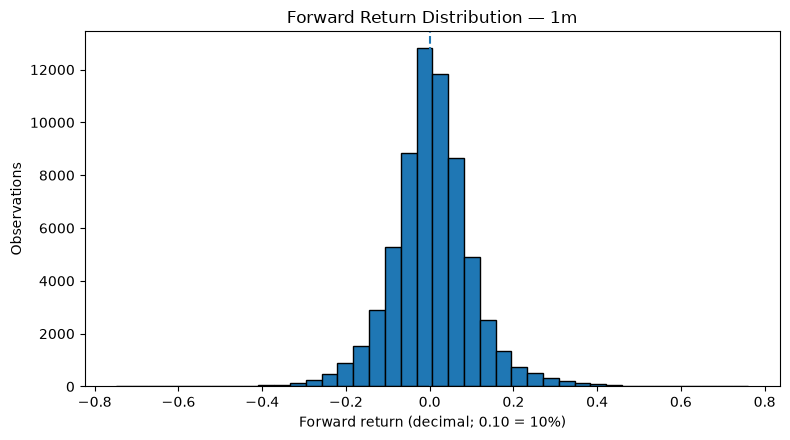

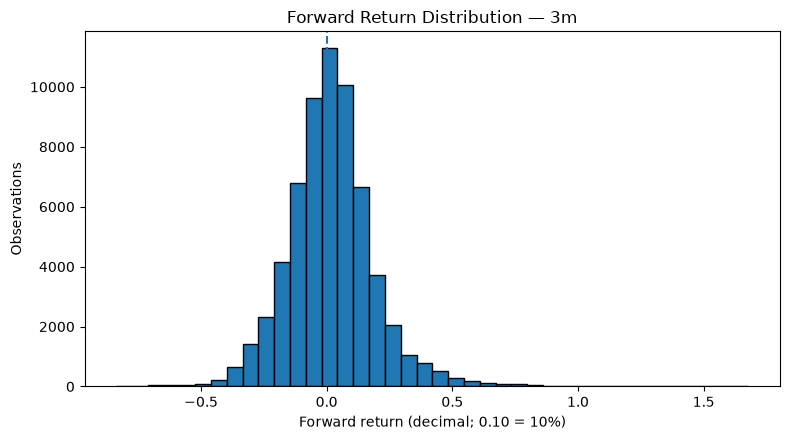

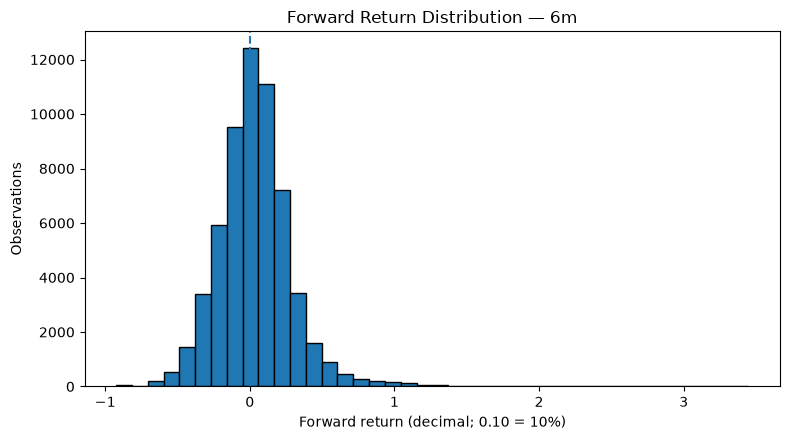

In [10]:
for horizon_name in HORIZONS:
    col = f"forward_return_{horizon_name}"
    values = targets[col].replace([np.inf, -np.inf], np.nan).dropna()
    if values.empty:
        print(f"No valid labels for {horizon_name}; skipping plot.")
        continue
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(values, bins=40, edgecolor="black")
    ax.axvline(0, linestyle="--")
    ax.set(title=f"Forward Return Distribution — {horizon_name}", xlabel="Forward return (decimal; 0.10 = 10%)", ylabel="Observations")
    plt.tight_layout()
    plt.show()

## 11. Check target leakage boundaries
The output file intentionally includes future-price and forward-return columns for label construction. Do not feed these columns into model predictors. A future modeling phase should build a feature table using only fields available as of each row's date.

In [11]:
target_columns = [
    c for c in targets.columns
    if c.startswith("future_price_")
    or c.startswith("forward_return_")
    or c.startswith("benchmark_future_price_")
    or c.startswith("benchmark_forward_return_")
    or c.startswith("relative_forward_return_")
    or c.startswith("outperforms_benchmark_")
]
leakage_register = pd.DataFrame({
    "column": target_columns,
    "role": [
        "future outcome / target construction only"
        if any(token in c for token in [
            "future_price", "forward_return", "relative_forward_return",
            "outperforms_benchmark"
        ]) else "review"
        for c in target_columns
    ],
    "allowed_as_predictor": False
})
display(leakage_register)
leakage_register.to_csv(REPORT_DIR / "target_leakage_register.csv", index=False)

,column,role,allowed_as_predictor
0,future_price_1m,future outcome / target construction only,False
1,forward_return_1m,future outcome / target construction only,False
2,future_price_3m,future outcome / target construction only,False
3,forward_return_3m,future outcome / target construction only,False
4,future_price_6m,future outcome / target construction only,False
5,forward_return_6m,future outcome / target construction only,False
6,benchmark_forward_return_1m,future outcome / target construction only,False
7,benchmark_forward_return_3m,future outcome / target construction only,False
8,benchmark_forward_return_6m,future outcome / target construction only,False
9,relative_forward_return_1m,future outcome / target construction only,False


## 12. Save target datasets

In [12]:
# Full target dataset preserves rows even when longer-horizon labels are unavailable.
full_targets_file = TARGET_DIR / "asx_forward_return_targets_all_rows.csv"
targets.to_csv(full_targets_file, index=False)

# A separate modeling-candidate dataset for the 3-month target; rows with no label are excluded.
# This is only a candidate label table, not a final model-ready dataset.
three_month_target = "forward_return_3m"
model_candidates = targets.loc[targets[three_month_target].notna()].copy()
candidate_file = TARGET_DIR / "asx_3m_return_model_candidates.csv"
model_candidates.to_csv(candidate_file, index=False)

print("Full target table:", full_targets_file)
print("3-month labeled candidate table:", candidate_file)
print("Rows in full target table:", len(targets))
print("Rows with observed 3-month target:", len(model_candidates))

Full target table: e:\Projects\Australian Stock Market Data Science Project\data\processed\model_targets\asx_forward_return_targets_all_rows.csv
3-month labeled candidate table: e:\Projects\Australian Stock Market Data Science Project\data\processed\model_targets\asx_3m_return_model_candidates.csv
Rows in full target table: 65771
Rows with observed 3-month target: 62495


## 13. Final validation summary

In [13]:
summary = pd.DataFrame([{
    "company_price_rows": int(len(prices)),
    "unique_company_tickers": int(prices["ticker"].nunique()),
    "benchmark_status": benchmark_status,
    "date_min": str(prices["date"].min()),
    "date_max": str(prices["date"].max()),
    "valid_1m_labels": int(targets["forward_return_1m"].notna().sum()),
    "valid_3m_labels": int(targets["forward_return_3m"].notna().sum()),
    "valid_6m_labels": int(targets["forward_return_6m"].notna().sum()),
    "relative_3m_labels": int(targets["relative_forward_return_3m"].notna().sum()) if "relative_forward_return_3m" in targets else 0,
    "target_columns_excluded_from_predictors": len(target_columns)
}])
display(summary)
summary.to_csv(REPORT_DIR / "phase9_target_engineering_summary.csv", index=False)

print("Target engineering reports saved to:", REPORT_DIR)
print("PHASE 9 TARGET ENGINEERING COMPLETED.")
print("Before modeling, verify target coverage and build predictors from information available on each prediction date.")

,company_price_rows,unique_company_tickers,benchmark_status,date_min,date_max,valid_1m_labels,valid_3m_labels,valid_6m_labels,relative_3m_labels,target_columns_excluded_from_predictors
0,65771,52,loaded,2021-10-19 00:00:00,2026-10-19 00:00:00,64679,62495,59219,62495,15


Target engineering reports saved to: e:\Projects\Australian Stock Market Data Science Project\reports\target_engineering
PHASE 9 TARGET ENGINEERING COMPLETED.
Before modeling, verify target coverage and build predictors from information available on each prediction date.
